# Healthy vs Rotten Fruit Classifier (CNN from scratch)
**Deep Learning Lab project.** Upload a fruit photo and the model says **healthy** or **rotten**.

**Before running:** `Runtime > Change runtime type > T4 GPU`, then run cells from top to bottom.

**Steps in this notebook**
1. Load the data
2. Visualize the data
3. Preprocess the data (resize, scale, split, augment)
4. Build a CNN
5. Train the model
6. Evaluate the model
7. Predict on your own photo

## 1. Load the data
We import the libraries, download the dataset from Kaggle, and give every image a label:
- `0` = healthy
- `1` = rotten

The dataset's folders are named like `Apple__Healthy` and `Apple__Rotten`, so we read the label from the folder name.

In [31]:
!pip -q install kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Fix the random seeds so results are repeatable
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [32]:
import kagglehub

# Download the dataset (same code you copied from Kaggle)
path = kagglehub.dataset_download("muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fruit-and-vegetable-disease-healthy-vs-rotten' dataset.
Path to dataset files: /kaggle/input/fruit-and-vegetable-disease-healthy-vs-rotten


In [33]:
image_paths = []
labels = []

for folder, _, files in os.walk(path):
    # Use ONLY the last folder name (e.g. "Apple__Rotten"), not the full path,
    # because the dataset's own name contains both "healthy" and "rotten"
    folder_name = os.path.basename(folder).lower()

    if "rotten" in folder_name:
        label = 1          # rotten
    elif "healthy" in folder_name:
        label = 0          # healthy
    else:
        continue           # not an image class folder, skip

    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, f))
            labels.append(label)

df = pd.DataFrame({"path": image_paths, "label": labels})
df["name"] = df["label"].map({0: "healthy", 1: "rotten"})

print("Total images:", len(df))
print(df["name"].value_counts())

# Safety check: we need BOTH classes, otherwise the labels were read wrongly
assert df["label"].nunique() == 2, "Only one class found! Print os.listdir(path) and check the folder names."
df.head()

Total images: 29277
name
rotten     15493
healthy    13784
Name: count, dtype: int64


,path,label,name
0,/kaggle/input/fruit-and-vegetable-disease-heal...,1,rotten
1,/kaggle/input/fruit-and-vegetable-disease-heal...,1,rotten
2,/kaggle/input/fruit-and-vegetable-disease-heal...,1,rotten
3,/kaggle/input/fruit-and-vegetable-disease-heal...,1,rotten
4,/kaggle/input/fruit-and-vegetable-disease-heal...,1,rotten


## 2. Visualize the data
Before training, always look at your data. We check two things:
- **Is it balanced?** If 95% of images were healthy, a model that always says "healthy" would score 95% without learning anything.
- **What do the images look like?**

name
rotten     15493
healthy    13784
Name: count, dtype: int64


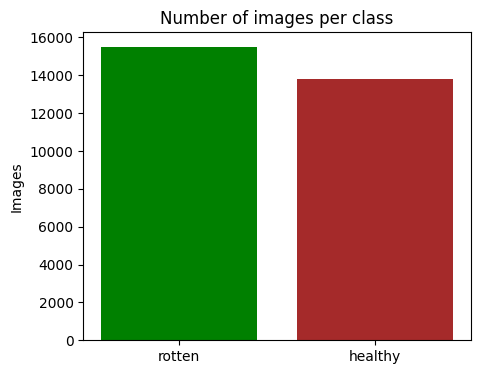

In [34]:
# Bar chart: how many images per class?
counts = df["name"].value_counts()
print(counts)

plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=["green", "brown"])
plt.title("Number of images per class")
plt.ylabel("Images")
plt.show()

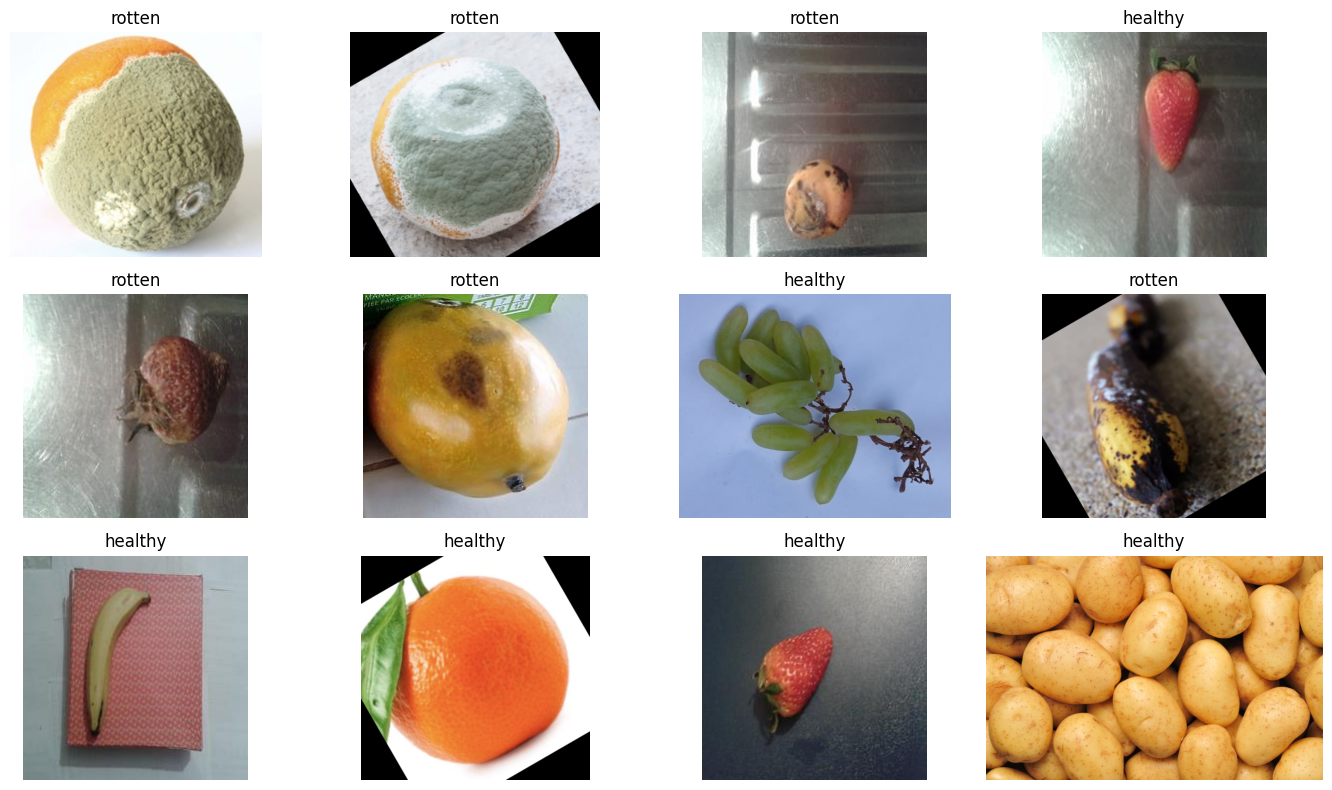

In [35]:
# Show 12 random images with their labels
sample = df.sample(12, random_state=1)

plt.figure(figsize=(14, 8))
for i, (_, row) in enumerate(sample.iterrows()):
    plt.subplot(3, 4, i + 1)
    plt.imshow(plt.imread(row["path"]))
    plt.title(row["name"])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Preprocess the data
Neural networks need inputs of the **same size and a small range**, so we:

1. **Resize** every image to 128 x 128 pixels.
2. **Scale** pixel values from 0-255 down to 0-1 (this helps gradient descent train faster and more stably).
3. **Split** the data into three parts:
   - **Train (70%)**: the model learns from these.
   - **Validation (15%)**: we check progress during training and use it for early stopping.
   - **Test (15%)**: never seen during training; gives the honest final accuracy.
4. **Augment** the training images (random flip, rotation, zoom). This creates slightly different versions of the same image each epoch and reduces **overfitting**.

In [36]:
# Split: 70% train, 15% validation, 15% test
# stratify keeps the healthy/rotten ratio the same in every part
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

Train: 20493 | Validation: 4392 | Test: 4392


In [37]:
IMG_SIZE = 128     # every image becomes 128 x 128
BATCH_SIZE = 32    # the model looks at 32 images before updating its weights

def load_image(path, label):
    # Read the file, decode it into pixel numbers, resize it
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, tf.cast(label, tf.float32)

def make_dataset(dataframe, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((dataframe["path"].values, dataframe["label"].values))
    if shuffle:
        ds = ds.shuffle(len(dataframe), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()                     # skip any corrupted image files
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)
test_ds = make_dataset(test_df, shuffle=False)

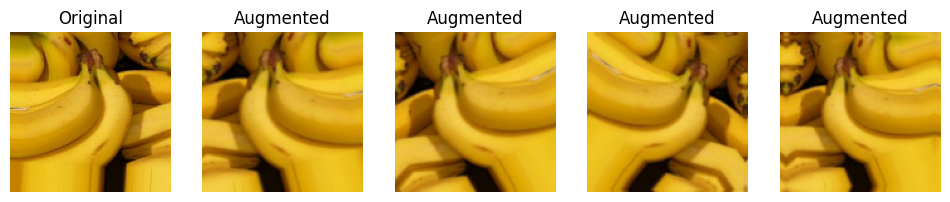

In [38]:
# Data augmentation: random changes applied ONLY while training
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Show what augmentation does to ONE image
img, lbl = next(iter(train_ds.unbatch().take(1)))
plt.figure(figsize=(12, 3))
plt.subplot(1, 5, 1)
plt.imshow(img.numpy().astype("uint8")); plt.title("Original"); plt.axis("off")
for i in range(4):
    plt.subplot(1, 5, i + 2)
    aug = data_augmentation(tf.expand_dims(img, 0), training=True)
    plt.imshow(aug[0].numpy().astype("uint8")); plt.title("Augmented"); plt.axis("off")
plt.show()

## 4. Build the CNN
A **Convolutional Neural Network** has two parts:

**Feature extractor (finds patterns in the image)**
- `Conv2D`: slides small filters (3x3) over the image to detect edges, colours and textures. Early layers find simple edges; deeper layers find complex shapes like dark rotten patches.
- `ReLU` activation: keeps positive values, sets negatives to 0. This adds non-linearity so the network can learn complex patterns.
- `MaxPooling2D`: shrinks the image by keeping the strongest value in each 2x2 block. This reduces computation.

**Classifier (makes the decision)**
- `Flatten`: turns the feature maps into one long vector.
- `Dense` (fully connected) layer: combines the features.
- `Dropout`: randomly switches off 50% of neurons during training so the network does not rely on any single neuron (regularization).
- Final `Dense(1, sigmoid)`: outputs a number between 0 and 1. Close to 0 means healthy, close to 1 means rotten.

In [39]:
model = keras.Sequential([
    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    data_augmentation,              # random flips/rotations (training only)
    layers.Rescaling(1.0 / 255),    # scale pixels from 0-255 to 0-1

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),   # 0 = healthy, 1 = rotten
])

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,289,665 (4.92 MB)

 Trainable params: 1,289,665 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model
Three choices to understand:

- **Loss function: binary cross-entropy.** It measures how wrong the predicted probability is for a two-class problem. A confident wrong answer gives a very high loss.
- **Optimizer: Adam.** An improved version of gradient descent (it uses momentum and adapts the step size for each weight). Backpropagation calculates the gradients, and Adam uses them to update the weights.
- **Early stopping.** If validation accuracy does not improve for 5 epochs, stop training and go back to the best weights. This prevents overfitting.

One **epoch** = the model has seen every training image once.

In [41]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",       # watch validation accuracy
    patience=5,                   # wait 5 epochs without improvement
    restore_best_weights=True,    # go back to the best version
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=7,
    callbacks=[early_stop],
)

Epoch 1/7
    640/Unknown 108s 164ms/step - accuracy: 0.6364 - loss: 0.6241

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


641/641 ━━━━━━━━━━━━━━━━━━━━ 128s 196ms/step - accuracy: 0.7033 - loss: 0.5628 - val_accuracy: 0.8028 - val_loss: 0.4372
Epoch 2/7
641/641 ━━━━━━━━━━━━━━━━━━━━ 124s 193ms/step - accuracy: 0.8143 - loss: 0.4167 - val_accuracy: 0.8286 - val_loss: 0.3572
Epoch 3/7
641/641 ━━━━━━━━━━━━━━━━━━━━ 119s 185ms/step - accuracy: 0.8522 - loss: 0.3481 - val_accuracy: 0.8825 - val_loss: 0.2965
Epoch 4/7
641/641 ━━━━━━━━━━━━━━━━━━━━ 118s 184ms/step - accuracy: 0.8778 - loss: 0.2948 - val_accuracy: 0.8975 - val_loss: 0.2524
Epoch 5/7
641/641 ━━━━━━━━━━━━━━━━━━━━ 121s 188ms/step - accuracy: 0.8918 - loss: 0.2572 - val_accuracy: 0.9137 - val_loss: 0.2204
Epoch 6/7
641/641 ━━━━━━━━━━━━━━━━━━━━ 118s 184ms/step - accuracy: 0.9039 - loss: 0.2350 - val_accuracy: 0.9258 - val_loss: 0.1929
Epoch 7/7
641/641 ━━━━━━━━━━━━━━━━━━━━ 201s 277ms/step - accuracy: 0.9131 - loss: 0.2200 - val_accuracy: 0.9344 - val_loss: 0.1792


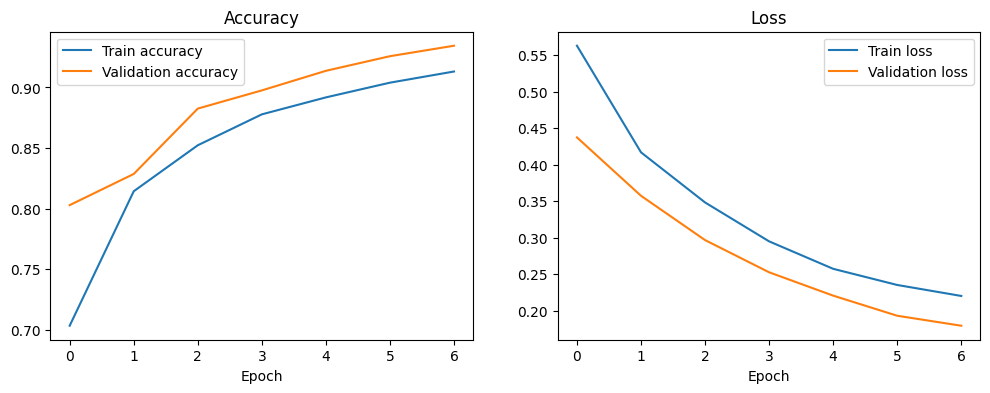

In [42]:
# Plot accuracy and loss for each epoch
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

**How to read these graphs**
- Both accuracy lines should go up, and both loss lines should go down.
- If training accuracy is much higher than validation accuracy, the model is **overfitting** (memorizing instead of learning).

## 6. Evaluate the model
We now use the **test set**, which the model has never seen, to get the real accuracy.

In [43]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nTest accuracy: {test_acc * 100:.2f}%")

if test_acc > 0.90:
    print("Target of 90% reached!")
else:
    print("Below 90%. Run the optional fallback cell at the bottom of this notebook.")

138/138 ━━━━━━━━━━━━━━━━━━━━ 23s 169ms/step - accuracy: 0.9212 - loss: 0.1870

Test accuracy: 92.12%
Target of 90% reached!


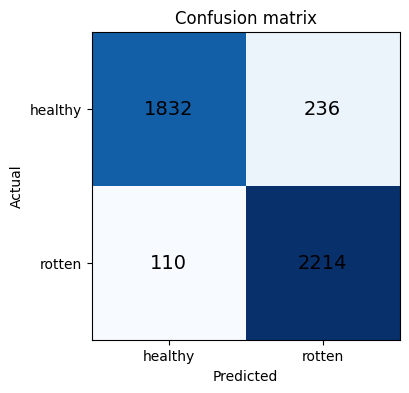

              precision    recall  f1-score   support

     healthy       0.94      0.89      0.91      2068
      rotten       0.90      0.95      0.93      2324

    accuracy                           0.92      4392
   macro avg       0.92      0.92      0.92      4392
weighted avg       0.92      0.92      0.92      4392



In [44]:
# Collect true labels and predictions for the whole test set
y_true = []
y_pred = []
for images, labels in test_ds:
    probs = model.predict(images, verbose=0).ravel()
    y_pred.extend((probs > 0.5).astype(int))     # above 0.5 means rotten
    y_true.extend(labels.numpy().astype(int))

# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["healthy", "rotten"]); plt.yticks([0, 1], ["healthy", "rotten"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()

print(classification_report(y_true, y_pred, target_names=["healthy", "rotten"]))

**Reading the confusion matrix**
- Diagonal numbers (top-left, bottom-right) are the **correct** predictions.
- Off-diagonal numbers are mistakes: a healthy fruit called rotten, or a rotten fruit called healthy.
- **Precision**: of the fruits predicted as X, how many really were X.
- **Recall**: of all the real X fruits, how many we found.

Number of mistakes: 346


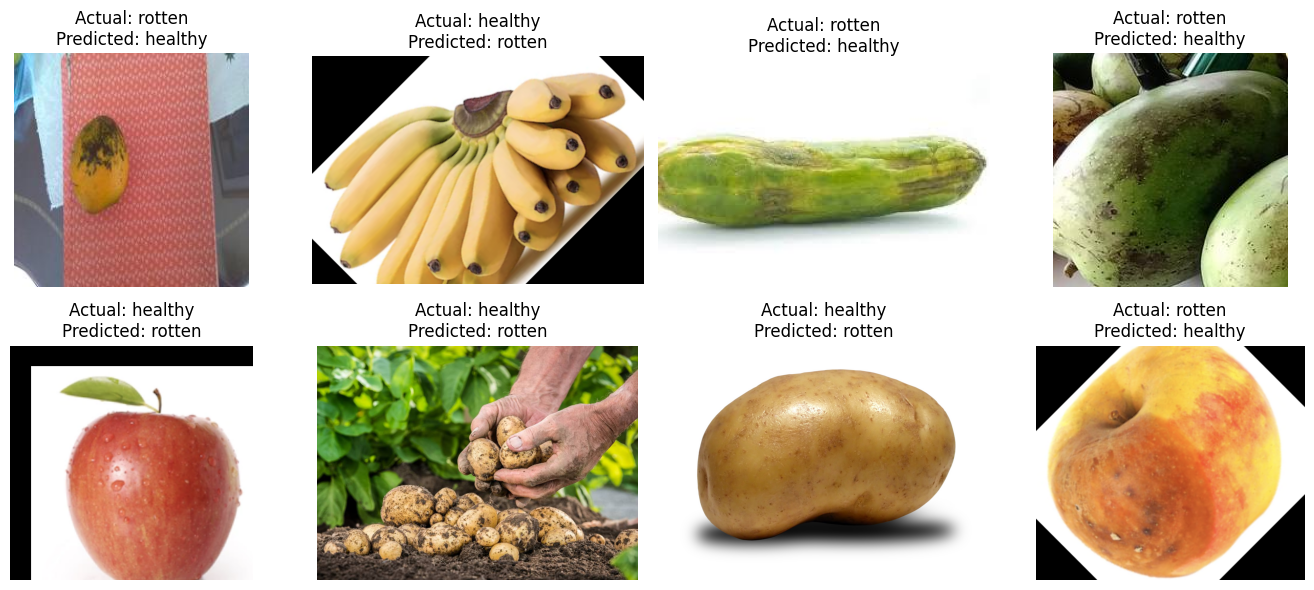

In [45]:
# Show some images the model got WRONG (useful for your report)
wrong = np.where(np.array(y_true) != np.array(y_pred))[0]
print("Number of mistakes:", len(wrong))

test_paths = list(test_df["path"])
names = ["healthy", "rotten"]
plt.figure(figsize=(14, 6))
for k, idx in enumerate(wrong[:8]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(plt.imread(test_paths[idx]))
    plt.title(f"Actual: {names[y_true[idx]]}\nPredicted: {names[y_pred[idx]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [46]:
# Save the trained model so you can reuse it without retraining
model.save("fruit_cnn.keras")
final_model = model      # the model used for predictions below

## 7. Predict on your own photo
Upload any fruit image. The model prints healthy or rotten with its confidence.

Tips: use a clear, well-lit photo with the fruit filling most of the frame.

Saving istockphoto-519974059-612x612.jpg to istockphoto-519974059-612x612.jpg


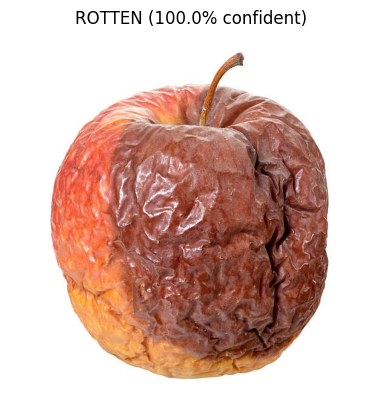

In [47]:
from google.colab import files

def predict_fruit(img_path):
    # Load and resize the image exactly like the training images
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    small = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    batch = tf.expand_dims(small, 0)                  # model expects a batch of images

    prob_rotten = float(final_model.predict(batch, verbose=0)[0][0])

    if prob_rotten > 0.5:
        result, confidence = "ROTTEN", prob_rotten
    else:
        result, confidence = "HEALTHY", 1 - prob_rotten

    plt.imshow(img.numpy().astype("uint8"))
    plt.title(f"{result} ({confidence * 100:.1f}% confident)")
    plt.axis("off")
    plt.show()

uploaded = files.upload()
for file_name in uploaded:
    predict_fruit(file_name)

Saving healthy-apple-recipes.jpg to healthy-apple-recipes.jpg


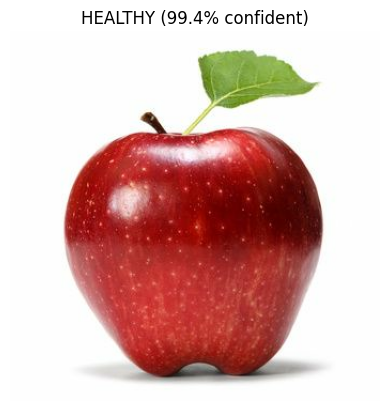

In [48]:
from google.colab import files

def predict_fruit(img_path):
    # Load and resize the image exactly like the training images
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    small = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    batch = tf.expand_dims(small, 0)                  # model expects a batch of images

    prob_rotten = float(final_model.predict(batch, verbose=0)[0][0])

    if prob_rotten > 0.5:
        result, confidence = "ROTTEN", prob_rotten
    else:
        result, confidence = "HEALTHY", 1 - prob_rotten

    plt.imshow(img.numpy().astype("uint8"))
    plt.title(f"{result} ({confidence * 100:.1f}% confident)")
    plt.axis("off")
    plt.show()

uploaded = files.upload()
for file_name in uploaded:
    predict_fruit(file_name)

Saving istockphoto-184952247-612x612.jpg to istockphoto-184952247-612x612.jpg


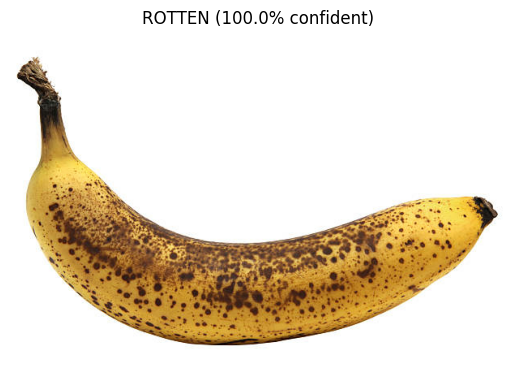

In [49]:
from google.colab import files

def predict_fruit(img_path):
    # Load and resize the image exactly like the training images
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    small = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    batch = tf.expand_dims(small, 0)                  # model expects a batch of images

    prob_rotten = float(final_model.predict(batch, verbose=0)[0][0])

    if prob_rotten > 0.5:
        result, confidence = "ROTTEN", prob_rotten
    else:
        result, confidence = "HEALTHY", 1 - prob_rotten

    plt.imshow(img.numpy().astype("uint8"))
    plt.title(f"{result} ({confidence * 100:.1f}% confident)")
    plt.axis("off")
    plt.show()

uploaded = files.upload()
for file_name in uploaded:
    predict_fruit(file_name)